# Rain and Irrigation from Satellite Soil Moisture
**Capstone Fall 2026 - Scope 2** · Snehal & Mohammad

**Goal:** tell from satellite soil moisture whether the soil got wet from **rain** or **irrigation**.

| Part | Region | Model |
|---|---|---|
| A | Region 1 (20 blocks + flow meter) | Irrigation |
| B | Region 2 (72 blocks + CIMIS 235) | Rain |
| C |         | Both together (tried) |
| D | – | **Final model** |

**How we test:** keep 25% of passes aside - tune each model on the rest - score on the kept-aside passes - double-check on all passes.

**Scores:** balanced accuracy and AUC run from 0.5 (guessing) to 1.0 (perfect).

## 1. Setup

In [2]:
%matplotlib inline
import ctypes
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, LeaveOneOut, RepeatedStratifiedKFold, cross_val_predict,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [3]:
DATA_DIR = Path.cwd()
OUT_DIR = DATA_DIR / "outputs" / "final_presentation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Region 1 (20 blocks): irrigation
R1_SOIL_FILE = DATA_DIR / "sm_avg_block_trend_20251101.0_20260926.0.xlsx"
R1_FLOW_FILE = DATA_DIR / "AvgSoilMoisture_block_trend_FirstQuarter2026.xlsx"
R1_RAIN_FILE = DATA_DIR / "CIMIS_Station105_Precp_20250801_20260925.xlsx"

# Region 2 (72 blocks): rain
R2_SOIL_FILE = DATA_DIR / "sm_avg_block_trend_20251027.0_20261022_new.csv"
R2_RAIN_FILE = DATA_DIR / "CIMIS_Station235_Precp_20251015_20261022.xlsx"

# Region 1 layout: row 0 = fallow (clean), row 1 = fallow next to almond, rows 2-3 = almond
R1_FALLOW_CONTROL = [f"0_{c}" for c in range(5)]
R1_ROW1 = [f"1_{c}" for c in range(5)]
R1_ALMOND = [f"{r}_{c}" for r in (2, 3) for c in range(5)]

# What counts as rain / irrigation
RAIN_WINDOW_DAYS, RAIN_MIN_MM = 3, 5.0    # 5+ mm in 3 days
IRRIGATION_WINDOW_DAYS, IRRIGATION_MIN_GALLONS = 2, 50_000  # 50,000+ gallons in 2 days

MISSING_CODE = -9999          # "no data" in region 2
VALID_RANGE = (0.0, 0.6)      # anything outside is impossible
OUTLIER_LIMIT = 0.10          # glitch threshold
REPEAT_CYCLE_DAYS = 12        # satellite repeats every 12 days

TEST_SIZE = 0.25              # 25% kept aside for testing
N_FOLDS, N_REPEATS = 5, 5     # tuning: 5 slices, repeated 5 times
RANDOM_SEED = 42              # same results every run

In [5]:
# Chart style
FALLOW_COLOR, ALMOND_COLOR, SOIL_COLOR = "#2a78d6", "#eb6834", "#8c5a3c"
RAIN_COLOR, FLOW_COLOR = "#1baf7a", "#6250d6"
MODEL_COLORS = {"Logistic Regression": "#eb6834", "Random Forest": "#1baf7a", "XGBoost": "#2a78d6"}
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
PASS_MARKERS = ["o", "s", "^", "D", "v"]


def style_axes(ax, title=None, ylabel=None):
    """Clean chart style."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK_SOFT)
    ax.tick_params(colors=INK_SOFT, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    if ylabel:
        ax.set_ylabel(ylabel, color=INK_SOFT, fontsize=9)


def save_figure(fig, name):
    """Save and show a chart."""
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

### Helper functions

In [6]:
def read_excel_safely(path, **kwargs):
    """Read an Excel file, even if it's open in Excel."""
    try:
        return pd.read_excel(path, **kwargs)
    except PermissionError:
        copy = Path(tempfile.gettempdir()) / f"copy_of_{path.name}"
        if not ctypes.windll.kernel32.CopyFileW(str(path), str(copy), False):
            raise PermissionError(f"{path.name} is locked - please close it in Excel and re-run.")
        return pd.read_excel(copy, **kwargs)


def load_daily_rain(path):
    """Daily rain (mm) from CIMIS."""
    cimis = read_excel_safely(path)
    cimis["date"] = pd.to_datetime(cimis["date"])
    return cimis.set_index("date")["DayPrecip_value"].sort_index()


def remove_bad_readings(sm, groups, limit=OUTLIER_LIMIT):
    """Remove readings that suddenly disagree with their neighbours."""
    clean, flagged = sm.copy(), 0
    for blocks in groups:
        group = sm[blocks]
        distance_today = group.sub(group.median(axis=1), axis=0)
        unusual = (distance_today - distance_today.median()).abs() > limit
        clean[blocks] = group.mask(unusual)
        flagged += int(unusual.sum().sum())
    return clean, flagged


def assign_passes(dates):
    """Dates 12 days apart belong to the same satellite pass."""
    phase = (dates - dates.min()).days % REPEAT_CYCLE_DAYS
    names = {p: f"Pass {i + 1}" for i, p in enumerate(pd.unique(phase))}
    return pd.Series([names[p] for p in phase], index=dates, name="pass")


def remove_pass_bias(sm, passes):
    """Even out the passes (each reads a little wetter or drier)."""
    offsets = sm.groupby(passes).mean() - sm.mean()
    return sm - offsets.loc[passes].set_axis(sm.index), offsets


def window_total(daily, end_dates, days):
    """Total rain or gallons in the days before each pass."""
    return pd.Series([daily.reindex(pd.date_range(end=d, periods=days)).sum(min_count=days) for d in end_dates],
                     index=end_dates)


def combine_events(rained, irrigated):
    """Two yes/no answers -> one event."""
    return pd.Series(np.select([rained & irrigated, rained, irrigated], ["Both", "Rain", "Irrigation"], "None"),
                     index=rained.index)

In [7]:
def model_grids(y_train):
    """The three models and the settings to try."""
    imbalance = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
    impute = lambda: SimpleImputer(strategy="median")        # fill small gaps
    return {
        "Logistic Regression": (
            make_pipeline(impute(), StandardScaler(),
                          LogisticRegression(class_weight="balanced", max_iter=2000)),
            {"logisticregression__C": [0.01, 0.1, 0.5, 1, 5]}),
        "Random Forest": (
            make_pipeline(impute(), RandomForestClassifier(class_weight="balanced", random_state=RANDOM_SEED)),
            {"randomforestclassifier__n_estimators": [100, 300],
             "randomforestclassifier__max_depth": [2, 3, 5],
             "randomforestclassifier__min_samples_leaf": [1, 3, 5]}),
        "XGBoost": (
            make_pipeline(impute(), XGBClassifier(scale_pos_weight=imbalance, eval_metric="logloss",
                                                  random_state=RANDOM_SEED)),
            {"xgbclassifier__max_depth": [2, 3],
             "xgbclassifier__learning_rate": [0.05, 0.1],
             "xgbclassifier__n_estimators": [100, 200]}),
    }


def tune_models(X_train, y_train):
    """Find the best settings using the training passes only."""
    tuned, rows = {}, []
    for name, (pipe, grid) in model_grids(y_train).items():
        search = GridSearchCV(pipe, grid, scoring="balanced_accuracy",
                              cv=RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS,
                                                         random_state=RANDOM_SEED))
        search.fit(X_train, y_train)
        tuned[name] = search.best_estimator_
        settings = ", ".join(f"{k.split('__')[1]}={v}" for k, v in search.best_params_.items())
        rows.append({"model": name, "best settings": settings,
                     "tuning score": round(search.best_score_, 3),
                     "how much it varies (+/-)": round(search.cv_results_["std_test_score"][search.best_index_], 2)})
    return tuned, pd.DataFrame(rows).set_index("model")


def scores(y_true, y_pred, y_prob=None):
    """Scores for one method."""
    y_true, y_pred = np.asarray(y_true, bool), np.asarray(y_pred, bool)
    return {"balanced_accuracy": round(balanced_accuracy_score(y_true, y_pred), 2),
            "precision": round(precision_score(y_true, y_pred, zero_division=0), 2),
            "recall": round(recall_score(y_true, y_pred, zero_division=0), 2),
            "f1": round(f1_score(y_true, y_pred, zero_division=0), 2),
            "roc_auc": round(roc_auc_score(y_true, y_prob), 2) if y_prob is not None and len(set(y_true)) == 2 else np.nan,
            "caught": f"{int((y_pred & y_true).sum())} of {int(y_true.sum())}",
            "false alarms": int((y_pred & ~y_true).sum())}


def leave_one_out(models, X, y):
    """Predict each pass with a model trained on all the others."""
    probs = {name: cross_val_predict(clone(m), X, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
             for name, m in models.items()}
    return probs, pd.DataFrame({name: scores(y, p >= 0.5, p) for name, p in probs.items()}).T


def plot_confusions(results, y_true, title, file):
    """Right/wrong table for each method."""
    fig, axes = plt.subplots(1, len(results), figsize=(3.6 * len(results), 3.4))
    for ax, (name, pred) in zip(np.atleast_1d(axes), results.items()):
        ConfusionMatrixDisplay.from_predictions(np.asarray(y_true).astype(int), np.asarray(pred).astype(int),
                                                display_labels=["no", "yes"], cmap="Blues", colorbar=False, ax=ax)
        ax.set_title(name, fontsize=10, color=INK)
        ax.set_xlabel("Predicted", color=INK_SOFT)
        ax.set_ylabel("Actual", color=INK_SOFT)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)
    fig.tight_layout()
    save_figure(fig, file)


def plot_roc(probs, y, title, file, rule_point=None):
    """ROC chart (AUC 1.0 = perfect, 0.5 = guessing)."""
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    for name, p in probs.items():
        far, hit, _ = roc_curve(y, p)
        ax.plot(far, hit, color=MODEL_COLORS[name], linewidth=2, label=f"{name} (AUC {roc_auc_score(y, p):.2f})")
    if rule_point is not None:
        ax.scatter(*rule_point, color=INK, s=50, zorder=3, label="Client rule")
    ax.plot([0, 1], [0, 1], color=INK_SOFT, linestyle="--", linewidth=1, label="Guessing (AUC 0.50)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False alarm rate", color=INK_SOFT, fontsize=9)
    style_axes(ax, title, "Hit rate (events caught)")
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    save_figure(fig, file)

---
# Part A: Irrigation (Region 1)
Was the almond irrigated in the 2 days before the pass? Rows 0–1 are fallow, rows 2–3 almond.

## A1. Load the data

In [8]:
def load_region1_soil():
    sm = read_excel_safely(R1_SOIL_FILE)
    sm["date"] = pd.to_datetime(sm["date"].astype(int).astype(str), format="%Y%m%d")
    return sm.set_index("date").sort_index()


def load_daily_flow():
    """Gallons pumped per day (flow rate x minutes)."""
    flow = read_excel_safely(R1_FLOW_FILE, sheet_name="Flow Meter Readings")
    flow.columns = ["time", "gpm"]
    flow = flow.sort_values("time")
    minutes = flow["time"].diff().shift(-1).dt.total_seconds() / 60
    flow["gallons"] = flow["gpm"] * minutes.clip(upper=60).fillna(minutes.median())
    return flow.groupby(flow["time"].dt.normalize())["gallons"].sum()


r1_soil = load_region1_soil()
r1_flow = load_daily_flow()
r1_rain = load_daily_rain(R1_RAIN_FILE)
print(f"Soil moisture: {len(r1_soil)} passes, {r1_soil.index.min():%d %b %Y} to {r1_soil.index.max():%d %b %Y}")
print(f"Flow meter   : {r1_flow.index.min():%d %b %Y} to {r1_flow.index.max():%d %b %Y}")
print(f"Rain (CIMIS 105): {r1_rain.index.min():%d %b %Y} to {r1_rain.index.max():%d %b %Y}")

Soil moisture: 73 passes, 01 Nov 2025 to 26 Sep 2026
Flow meter   : 12 Feb 2026 to 05 Sep 2026
Rain (CIMIS 105): 01 Aug 2025 to 25 Sep 2026


## A2. Clean the data
Remove glitches and even out the 3 satellite passes.

In [10]:
r1_clean, r1_flagged = remove_bad_readings(r1_soil, [R1_FALLOW_CONTROL, R1_ROW1, R1_ALMOND])
r1_passes = assign_passes(r1_clean.index)
r1_corr, r1_offsets = remove_pass_bias(r1_clean, r1_passes)
print(f"{r1_flagged} glitch readings removed")
print("Dates per pass:", r1_passes.value_counts().sort_index().to_dict())
pd.DataFrame({"fallow (row 0)": r1_offsets[R1_FALLOW_CONTROL].mean(axis=1),
              "almond": r1_offsets[R1_ALMOND].mean(axis=1)}).round(3).rename_axis("offset per pass")

5 glitch readings removed
Dates per pass: {'Pass 1': 26, 'Pass 2': 25, 'Pass 3': 22}


,fallow (row 0),almond
offset per pass,,
Pass 1,0.000,-0.006
Pass 2,0.008,0.003
Pass 3,-0.009,0.004


## A3. Features
How wet the fallow and almond are, how much they changed, and how evenly.

In [11]:
def build_irrigation_features(sm_raw, sm_corr, passes):
    f = pd.DataFrame(index=sm_corr.index)
    f["pass"] = passes
    f["fallow"] = sm_corr[R1_FALLOW_CONTROL].mean(axis=1)
    f["almond"] = sm_corr[R1_ALMOND].mean(axis=1)
    f["almond_minus_fallow"] = f["almond"] - f["fallow"]
    for col in ["fallow", "almond", "almond_minus_fallow"]:
        f[f"change_{col}"] = f[col].diff()
    raw = pd.DataFrame({"fallow": sm_raw[R1_FALLOW_CONTROL].mean(axis=1), "almond": sm_raw[R1_ALMOND].mean(axis=1)})
    raw["almond_minus_fallow"] = raw["almond"] - raw["fallow"]
    for col in raw.columns:
        f[f"same_pass_change_{col}"] = raw[col].groupby(passes).diff()
    f["fallow_spread"] = sm_corr[R1_FALLOW_CONTROL].std(axis=1)
    f["almond_spread"] = sm_corr[R1_ALMOND].std(axis=1)
    change = sm_corr.diff()
    f["share_of_blocks_wetter"] = (change > 0).where(change.notna()).astype(float).mean(axis=1)
    f.loc[f.index[0], "share_of_blocks_wetter"] = np.nan
    f["days_since_last_pass"] = f.index.to_series().diff().dt.days
    return f


irr_features = build_irrigation_features(r1_clean, r1_corr, r1_passes)
IRR_FEATURES = [c for c in irr_features.columns if c != "pass"]
print(f"{len(IRR_FEATURES)} features:", ", ".join(IRR_FEATURES))

13 features: fallow, almond, almond_minus_fallow, change_fallow, change_almond, change_almond_minus_fallow, same_pass_change_fallow, same_pass_change_almond, same_pass_change_almond_minus_fallow, fallow_spread, almond_spread, share_of_blocks_wetter, days_since_last_pass


## A4. Labels
Irrigated = at least 50,000 gallons in the 2 days before the pass.

In [12]:
irr_data = irr_features.copy()
irr_data["flow_gallons"] = window_total(r1_flow, irr_data.index, IRRIGATION_WINDOW_DAYS)
irr_data["irrigated"] = (irr_data["flow_gallons"] >= IRRIGATION_MIN_GALLONS).where(irr_data["flow_gallons"].notna())
irr_data["rain_mm"] = window_total(r1_rain, irr_data.index, RAIN_WINDOW_DAYS)
irr_data["rained"] = (irr_data["rain_mm"] >= RAIN_MIN_MM).where(irr_data["rain_mm"].notna())
irr_labelled = irr_data[irr_data["irrigated"].notna()]
print("Irrigation labels:", irr_labelled["irrigated"].value_counts().rename({True: "irrigated", False: "not irrigated"}).to_dict())

Irrigation labels: {'irrigated': 32, 'not irrigated': 14}


## A5. Look at the data

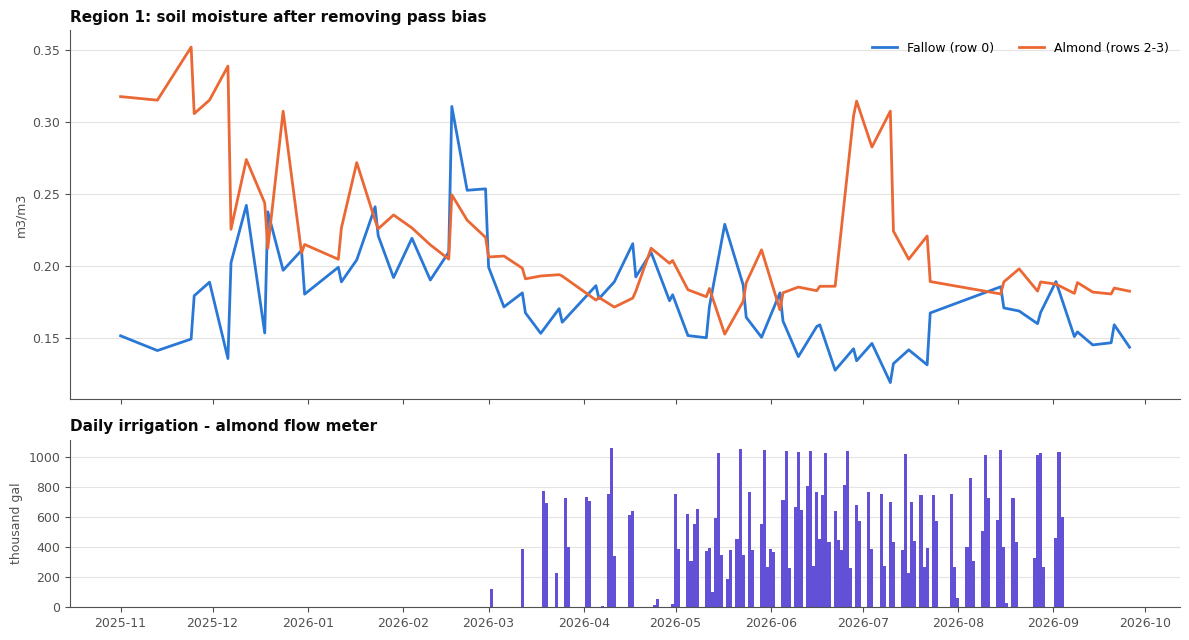

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax = axes[0]
for name, color, label in [("fallow", FALLOW_COLOR, "Fallow (row 0)"), ("almond", ALMOND_COLOR, "Almond (rows 2-3)")]:
    ax.plot(irr_data.index, irr_data[name], color=color, linewidth=2, label=label)
ax.legend(frameon=False, ncol=2, fontsize=9, loc="upper right")
style_axes(ax, "Region 1: soil moisture after removing pass bias", "m3/m3")
axes[1].bar(r1_flow.index, r1_flow / 1000, width=1, color=FLOW_COLOR)
style_axes(axes[1], "Daily irrigation - almond flow meter", "thousand gal")
fig.tight_layout()
save_figure(fig, "A1_region1_timeline.png")

## A6. Keep 25% aside for testing

In [14]:
X_irr, y_irr = irr_labelled[IRR_FEATURES], irr_labelled["irrigated"].astype(int)
X_irr_train, X_irr_test, y_irr_train, y_irr_test = train_test_split(
    X_irr, y_irr, test_size=TEST_SIZE, stratify=y_irr, random_state=RANDOM_SEED)
pd.DataFrame({"passes": [len(y_irr_train), len(y_irr_test)],
              "irrigated": [int(y_irr_train.sum()), int(y_irr_test.sum())],
              "not irrigated": [int((y_irr_train == 0).sum()), int((y_irr_test == 0).sum())]},
             index=["training set", "test set"])

,passes,irrigated,not irrigated
training set,34,24,10
test set,12,8,4


## A7. Tune each model
If two models are closer than the +/- value, it's a tie.

In [15]:
irr_models, irr_tuning = tune_models(X_irr_train, y_irr_train)
irr_tuning

,best settings,tuning score,how much it varies (+/-)
model,,,
Logistic Regression,C=5,0.715,0.15
Random Forest,"max_depth=2, min_samples_leaf=3, n_estimators=300",0.639,0.20
XGBoost,"learning_rate=0.05, max_depth=2, n_estimators=200",0.720,0.23


## A8. Test results
Compared with the client rule and an "it's summer" guess.

In [17]:
irr_cut = X_irr_train["almond_minus_fallow"].median()   # from the training passes only
irr_test_preds = {
    "Client rule": (X_irr_test["almond_minus_fallow"] > irr_cut).values,
    "It's summer": X_irr_test.index.month.isin(range(3, 10)),
}
irr_test_probs = {}
for name, model in irr_models.items():
    irr_test_probs[name] = model.predict_proba(X_irr_test)[:, 1]
    irr_test_preds[name] = irr_test_probs[name] >= 0.5
irr_test_results = pd.DataFrame({name: scores(y_irr_test, pred, irr_test_probs.get(name))
                                 for name, pred in irr_test_preds.items()}).T
irr_test_results.to_csv(OUT_DIR / "A_irrigation_test_results.csv")
irr_test_results

,balanced_accuracy,precision,recall,f1,roc_auc,caught,false alarms
Client rule,0.75,0.8,1.0,0.89,NaN,8 of 8,2
It's summer,0.62,0.73,1.0,0.84,NaN,8 of 8,3
Logistic Regression,0.5,0.67,0.75,0.71,0.78,6 of 8,3
Random Forest,0.75,0.8,1.0,0.89,0.72,8 of 8,2
XGBoost,0.75,0.8,1.0,0.89,0.75,8 of 8,2


Best irrigation model (picked during tuning): XGBoost


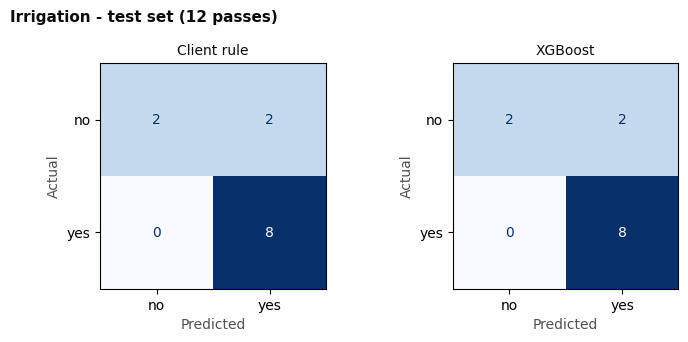

In [18]:
IRR_BEST = irr_tuning["tuning score"].idxmax()   # picked during tuning, not on the test set
print(f"Best irrigation model (picked during tuning): {IRR_BEST}")
plot_confusions({"Client rule": irr_test_preds["Client rule"], IRR_BEST: irr_test_preds[IRR_BEST]},
                y_irr_test, f"Irrigation - test set ({len(y_irr_test)} passes)", "A2_irrigation_confusion.png")

## A9. Double-check on all passes

In [19]:
irr_loo_probs, irr_loo_results = leave_one_out(irr_models, X_irr, y_irr)
rule_all = (X_irr["almond_minus_fallow"] > X_irr["almond_minus_fallow"].median()).values
irr_loo_results.loc["Client rule"] = pd.Series(scores(y_irr, rule_all))
irr_loo_results.loc["It's summer"] = pd.Series(scores(y_irr, X_irr.index.month.isin(range(3, 10))))
irr_loo_results.to_csv(OUT_DIR / "A_irrigation_loo_results.csv")
irr_loo_results

,balanced_accuracy,precision,recall,f1,roc_auc,caught,false alarms
Logistic Regression,0.63,0.79,0.69,0.73,0.71,22 of 32,6
Random Forest,0.63,0.76,0.91,0.83,0.76,29 of 32,9
XGBoost,0.75,0.83,0.94,0.88,0.79,30 of 32,6
Client rule,0.6,0.78,0.56,0.65,NaN,18 of 32,5
It's summer,0.64,0.76,1.0,0.86,NaN,32 of 32,10


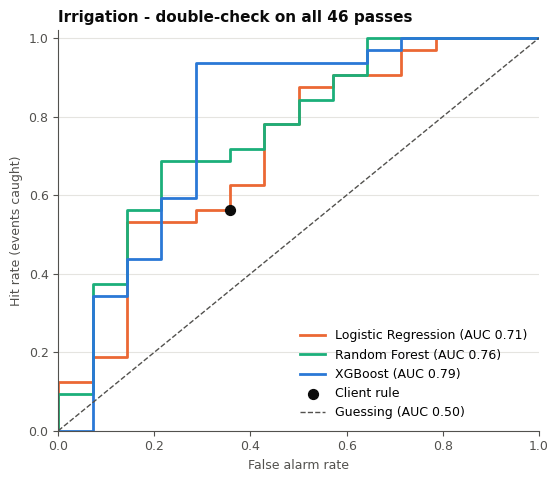

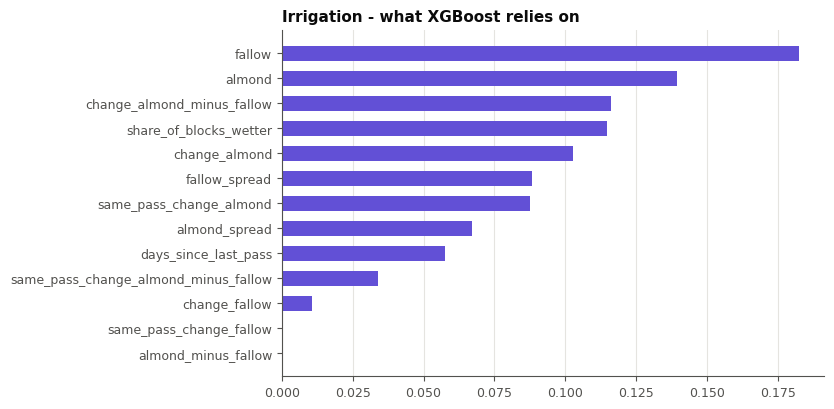

In [21]:
plot_roc(irr_loo_probs, y_irr, f"Irrigation - double-check on all {len(y_irr)} passes", "A3_irrigation_roc.png",
         rule_point=(rule_all[y_irr.values == 0].mean(), rule_all[y_irr.values == 1].mean()))

# What the best model relies on most
best = clone(irr_models[IRR_BEST]).fit(X_irr, y_irr)
final_step = best[-1]
importance = pd.Series(np.abs(final_step.coef_[0]) if hasattr(final_step, "coef_") else final_step.feature_importances_,
                       index=IRR_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.values, color=FLOW_COLOR, height=0.6)
style_axes(ax, f"Irrigation - what {IRR_BEST} relies on")
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
save_figure(fig, "A4_irrigation_feature_importance.png")

---
# Part B: Rain (Region 2)
Did at least 5 mm fall in the 3 days before the pass? The crop layout is unknown, so all 72 blocks are used.

## B1. Load and clean the data
`-9999` means no data; 28 empty dates are dropped.

We remove incorrect readings and missing data.
- -9999 means the reading is missing.
- Values outside 0 to 0.6 are treated as invalid.
- 28 completely empty dates are removed.
- 36 unusual readings are removed.
- We correct differences between satellite passes because some passes may measure slightly wetter or drier than others

In [22]:
def load_region2_soil():
    sm = pd.read_csv(R2_SOIL_FILE)
    sm["date"] = pd.to_datetime(sm["date"].astype(int).astype(str), format="%Y%m%d")
    sm = sm.set_index("date").sort_index()
    total = len(sm)
    sm = sm.mask(sm == MISSING_CODE)
    sm = sm.mask((sm < VALID_RANGE[0]) | (sm > VALID_RANGE[1]))
    sm = sm.dropna(how="all")
    print(f"{total} dates in the file, {total - len(sm)} completely empty -> {len(sm)} usable")
    return sm


def row_groups(columns):
    """Blocks grouped by row."""
    groups = {}
    for block in columns:
        groups.setdefault(block.split("_")[0], []).append(block)
    return groups


r2_soil = load_region2_soil()
r2_rain = load_daily_rain(R2_RAIN_FILE)
R2_ROWS = row_groups(r2_soil.columns)
r2_clean, r2_flagged = remove_bad_readings(r2_soil, list(R2_ROWS.values()))
r2_passes = assign_passes(r2_clean.index)
r2_corr, _ = remove_pass_bias(r2_clean, r2_passes)
print(f"Grid: {len(R2_ROWS)} rows x {len(r2_soil.columns) // len(R2_ROWS)} columns | {r2_flagged} glitch readings removed")
print("Dates per pass:", r2_passes.value_counts().sort_index().to_dict())
print(f"Rain (CIMIS 235): {r2_rain.index.min():%d %b %Y} to {r2_rain.index.max():%d %b %Y}, total {r2_rain.sum():.0f} mm")

107 dates in the file, 28 completely empty -> 79 usable
Grid: 8 rows x 9 columns | 36 glitch readings removed
Dates per pass: {'Pass 1': 26, 'Pass 2': 27, 'Pass 3': 26}
Rain (CIMIS 235): 15 Oct 2025 to 22 Oct 2026, total 630 mm


## B2. Features
How wet the whole area is, how much it changed, and how many blocks got wetter.

In [23]:
def build_rain_features(sm_raw, sm_corr, passes):
    rows = row_groups(sm_corr.columns)
    f = pd.DataFrame(index=sm_corr.index)
    f["wetness"] = sm_corr.mean(axis=1)
    f["change_wetness"] = f["wetness"].diff()
    f["same_pass_change_wetness"] = sm_raw.mean(axis=1).groupby(passes).diff()
    change = sm_corr.diff()
    f["median_block_change"] = change.median(axis=1)
    f["share_of_blocks_wetter"] = (change > 0).where(change.notna()).astype(float).mean(axis=1)
    row_change = pd.DataFrame({r: sm_corr[b].mean(axis=1) for r, b in rows.items()}).diff()
    f["share_of_rows_wetter"] = (row_change > 0).where(row_change.notna()).astype(float).mean(axis=1)
    f.loc[f.index[0], ["share_of_blocks_wetter", "share_of_rows_wetter"]] = np.nan
    f["spread"] = sm_corr.std(axis=1)
    f["days_since_last_pass"] = f.index.to_series().diff().dt.days
    return f


rain_data = build_rain_features(r2_clean, r2_corr, r2_passes)
RAIN_FEATURES = list(rain_data.columns)
rain_data["pass"] = r2_passes
rain_data["rain_mm"] = window_total(r2_rain, rain_data.index, RAIN_WINDOW_DAYS)
rain_data["rained"] = (rain_data["rain_mm"] >= RAIN_MIN_MM).where(rain_data["rain_mm"].notna())
rain_labelled = rain_data[rain_data["rained"].notna()]
print("Rain labels:", rain_labelled["rained"].value_counts().rename({True: "rain", False: "no rain"}).to_dict())

Rain labels: {'no rain': 67, 'rain': 12}


## B3. Look at the data

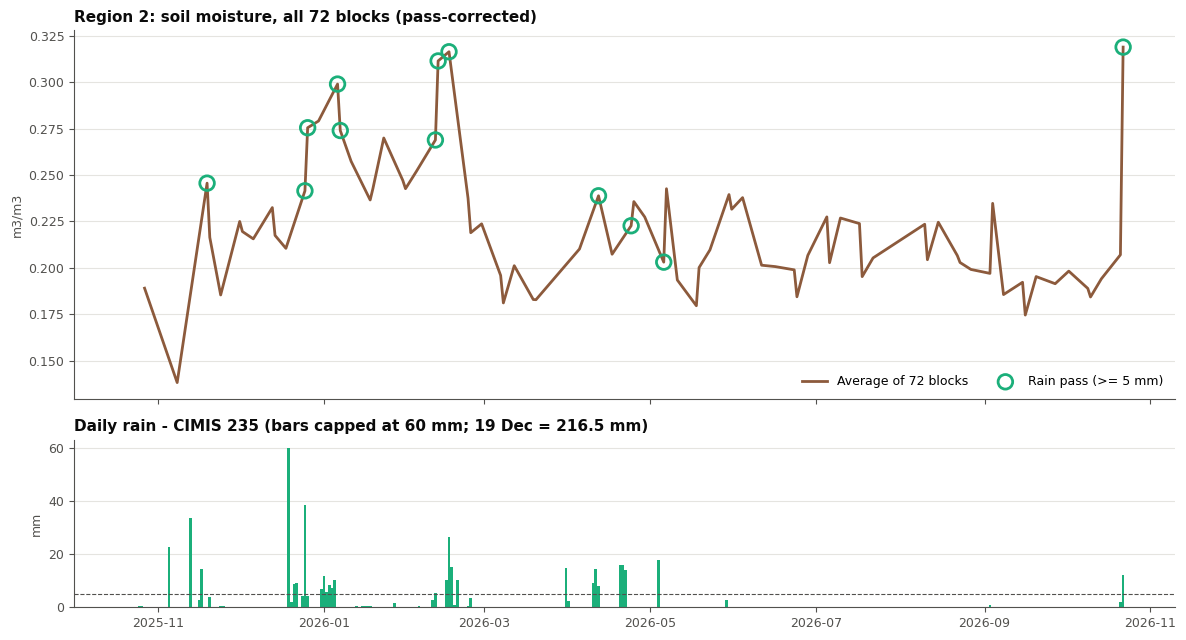

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax = axes[0]
ax.plot(rain_data.index, rain_data["wetness"], color=SOIL_COLOR, linewidth=2, label="Average of 72 blocks")
rainy = rain_data[rain_data["rained"] == True]
ax.scatter(rainy.index, rainy["wetness"], s=110, facecolor="none", edgecolor=RAIN_COLOR, linewidth=2, zorder=3,
           label="Rain pass (>= 5 mm)")
ax.legend(frameon=False, ncol=2, fontsize=9, loc="lower right")
style_axes(ax, "Region 2: soil moisture, all 72 blocks (pass-corrected)", "m3/m3")
window = slice(rain_data.index.min() - pd.Timedelta(days=7), rain_data.index.max())
axes[1].bar(r2_rain.loc[window].index, r2_rain.loc[window].clip(upper=60), width=1, color=RAIN_COLOR)
axes[1].axhline(RAIN_MIN_MM, color=INK_SOFT, linewidth=0.8, linestyle="--")
style_axes(axes[1], "Daily rain - CIMIS 235 (bars capped at 60 mm; 19 Dec = 216.5 mm)", "mm")
fig.tight_layout()
save_figure(fig, "B1_region2_timeline.png")

## B4. Keep 25% aside for testing

In [25]:
X_rain, y_rain = rain_labelled[RAIN_FEATURES], rain_labelled["rained"].astype(int)
X_rain_train, X_rain_test, y_rain_train, y_rain_test = train_test_split(
    X_rain, y_rain, test_size=TEST_SIZE, stratify=y_rain, random_state=RANDOM_SEED)
pd.DataFrame({"passes": [len(y_rain_train), len(y_rain_test)],
              "rain": [int(y_rain_train.sum()), int(y_rain_test.sum())],
              "no rain": [int((y_rain_train == 0).sum()), int((y_rain_test == 0).sum())]},
             index=["training set", "test set"])

,passes,rain,no rain
training set,59,9,50
test set,20,3,17


## B5. Tune each model

In [26]:
rain_models, rain_tuning = tune_models(X_rain_train, y_rain_train)
rain_tuning

,best settings,tuning score,how much it varies (+/-)
model,,,
Logistic Regression,C=0.1,0.802,0.16
Random Forest,"max_depth=2, min_samples_leaf=5, n_estimators=300",0.804,0.18
XGBoost,"learning_rate=0.1, max_depth=2, n_estimators=200",0.768,0.18


## B6. Test results
Compared with the client rule (at least 80% of blocks wetter).

In [27]:
rain_test_preds = {"Client rule": (X_rain_test["share_of_blocks_wetter"] >= 0.8).values}
rain_test_probs = {}
for name, model in rain_models.items():
    rain_test_probs[name] = model.predict_proba(X_rain_test)[:, 1]
    rain_test_preds[name] = rain_test_probs[name] >= 0.5
rain_test_results = pd.DataFrame({name: scores(y_rain_test, pred, rain_test_probs.get(name))
                                  for name, pred in rain_test_preds.items()}).T
rain_test_results.to_csv(OUT_DIR / "B_rain_test_results.csv")
rain_test_results

,balanced_accuracy,precision,recall,f1,roc_auc,caught,false alarms
Client rule,0.66,0.25,0.67,0.36,NaN,2 of 3,6
Logistic Regression,0.72,0.33,0.67,0.44,0.8,2 of 3,4
Random Forest,0.72,0.33,0.67,0.44,0.69,2 of 3,4
XGBoost,0.75,0.4,0.67,0.5,0.76,2 of 3,3


Best rain model (picked during tuning): Random Forest


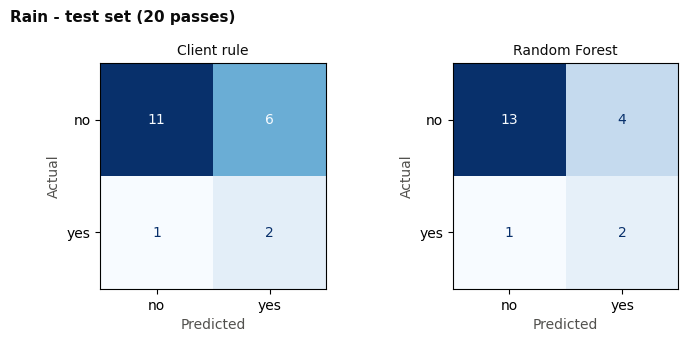

In [28]:
RAIN_BEST = rain_tuning["tuning score"].idxmax()
print(f"Best rain model (picked during tuning): {RAIN_BEST}")
plot_confusions({"Client rule": rain_test_preds["Client rule"], RAIN_BEST: rain_test_preds[RAIN_BEST]},
                y_rain_test, f"Rain - test set ({len(y_rain_test)} passes)", "B2_rain_confusion.png")

## B7. Double-check on all passes

In [29]:
rain_loo_probs, rain_loo_results = leave_one_out(rain_models, X_rain, y_rain)
rain_rule_all = (X_rain["share_of_blocks_wetter"] >= 0.8).values
rain_loo_results.loc["Client rule"] = pd.Series(scores(y_rain, rain_rule_all))
rain_loo_results.to_csv(OUT_DIR / "B_rain_loo_results.csv")
rain_loo_results

,balanced_accuracy,precision,recall,f1,roc_auc,caught,false alarms
Logistic Regression,0.78,0.41,0.75,0.53,0.84,9 of 12,13
Random Forest,0.8,0.67,0.67,0.67,0.79,8 of 12,4
XGBoost,0.71,0.55,0.5,0.52,0.85,6 of 12,5
Client rule,0.67,0.35,0.5,0.41,NaN,6 of 12,11


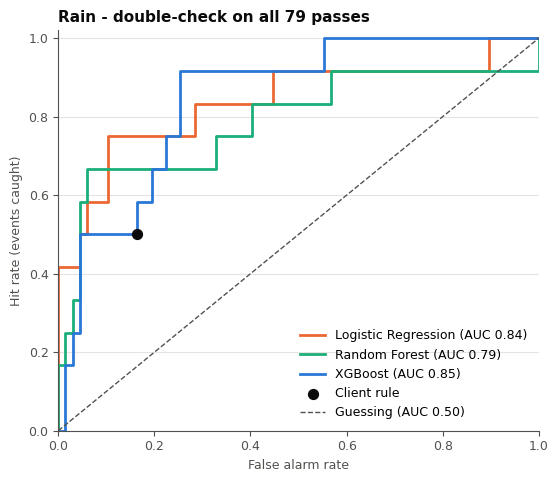

In [30]:
plot_roc(rain_loo_probs, y_rain, f"Rain - double-check on all {len(y_rain)} passes", "B3_rain_roc.png",
         rule_point=(rain_rule_all[y_rain.values == 0].mean(), rain_rule_all[y_rain.values == 1].mean()))